# *Forest Coverage in India as of 2019, Visualized in Map using Geopandas*
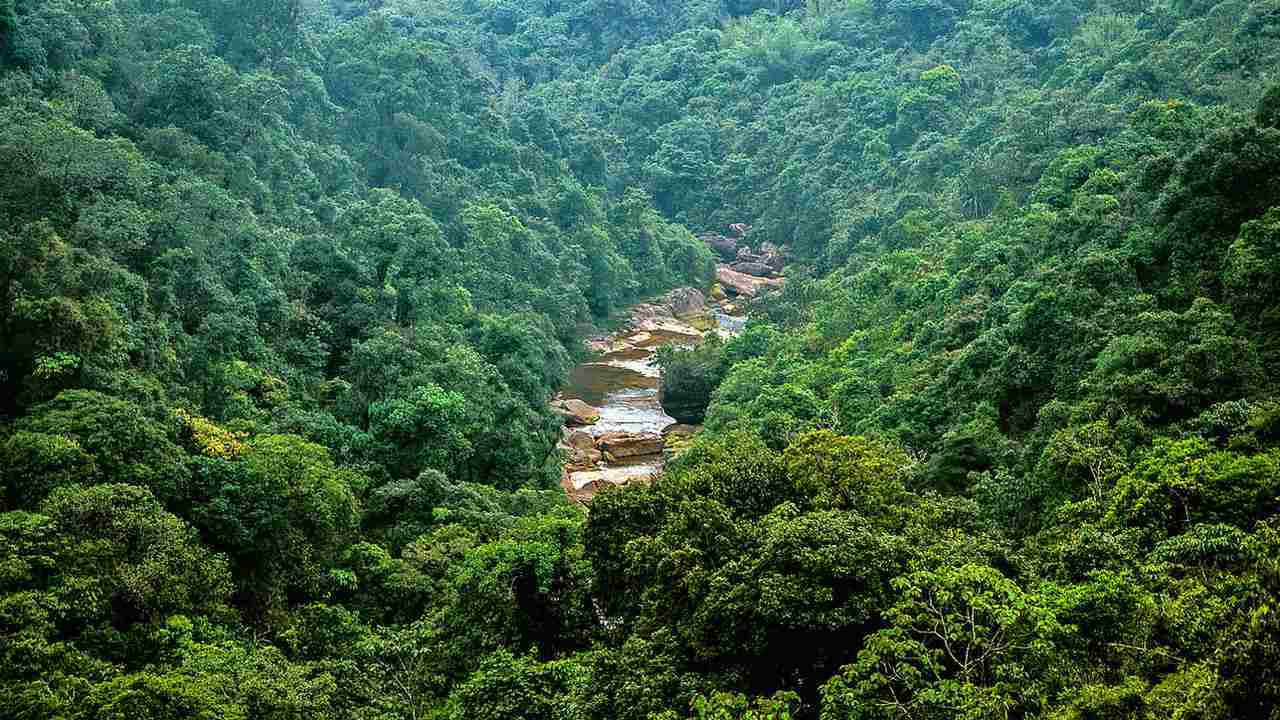

In [1]:
!pip install openpyxl
import pandas as pd
import seaborn as sns
import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import plotly.express as px

     |████████████████████████████████| 243 kB 1.1 MB/s 


### *Importing our shape file and our data*

In [2]:
df = pd.read_excel('../input/forest-cover-in-india/Forest.xlsx')
shp_gdf = gpd.read_file('../input/india-gis-data/India States/Indian_states.shp')

In [3]:
df.head(40)

,State/UTs,Geographical area,Very dense forest,Mod. dense forest,Open forest,Total forest,Percentage of geographical area,Scrub
0,Andhra Pradesh,"1,62,968","1,994","13,938","13,205","29,137",17.88,"8,255"
1,Arunachal Pradesh,"83,743","21,095","30,557","15,036","66,688",79.63,229
2,Assam,"78,438","2,795","10,279","15,253","28,327",36.11,173
3,Bihar,"94,163",333,"3,280","3,693","7,306",7.76,250
4,Chhattisgarh,"1,35,192","7,068","32,198","16,345","55,611",41.13,610
5,Delhi,"1,483",6.72,56.42,132.30,195.44,13.18,0.30
6,Goa,"3,702",538,576,"1,123","2,237",60.43,0
7,Gujarat,"1,96,244",378,"5,092","9,387","14,857",7.57,"2,994"
8,Haryana,"44,212",28,451,"1,123","1,602",3.62,154
9,Himachal Pradesh,"55,673","3,113","7,126","5,195","15,434",27.72,315


### *Renaming the states in our dataset to match the shape file*

In [4]:
df1 = df[['State/UTs', 'Percentage of geographical area']]
df1['State/UTs'][30] = 'Andaman & Nicobar Island'
df1['State/UTs'][1] = 'Arunanchal Pradesh'
df1['State/UTs'][32] = 'Dadara & Nagar Havelli'
df1['State/UTs'][5] = 'NCT of Delhi'

/opt/conda/lib/python3.7/site-packages/ipykernel_launcher.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  
/opt/conda/lib/python3.7/site-packages/IPython/core/interactiveshell.py:3441: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  exec(code_obj, self.user_global_ns, self.user_ns)
/opt/conda/lib/python3.7/site-packages/ipykernel_launcher.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  This is separate from the ipykernel package 

In [5]:
merged = shp_gdf.set_index('st_nm').join(df1.set_index('State/UTs'))
merged.head(40)

,geometry,Percentage of geographical area
st_nm,,
Andaman & Nicobar Island,"MULTIPOLYGON (((93.71976 7.20707, 93.71909 7.2...",81.74
Arunanchal Pradesh,"POLYGON ((96.16261 29.38078, 96.16860 29.37432...",79.63
Assam,"MULTIPOLYGON (((89.74323 26.30362, 89.74290 26...",36.11
Bihar,"MULTIPOLYGON (((84.50720 24.26323, 84.50355 24...",7.76
Chandigarh,"POLYGON ((76.84147 30.75996, 76.83599 30.73623...",19.32
Chhattisgarh,"POLYGON ((83.33532 24.09885, 83.35346 24.09627...",41.13
Dadara & Nagar Havelli,"POLYGON ((73.20657 20.12216, 73.20797 20.10650...",42.16
Daman & Diu,"MULTIPOLYGON (((72.89335 20.44539, 72.89281 20...",18.46
Goa,"MULTIPOLYGON (((74.11918 14.75344, 74.11350 14...",60.43


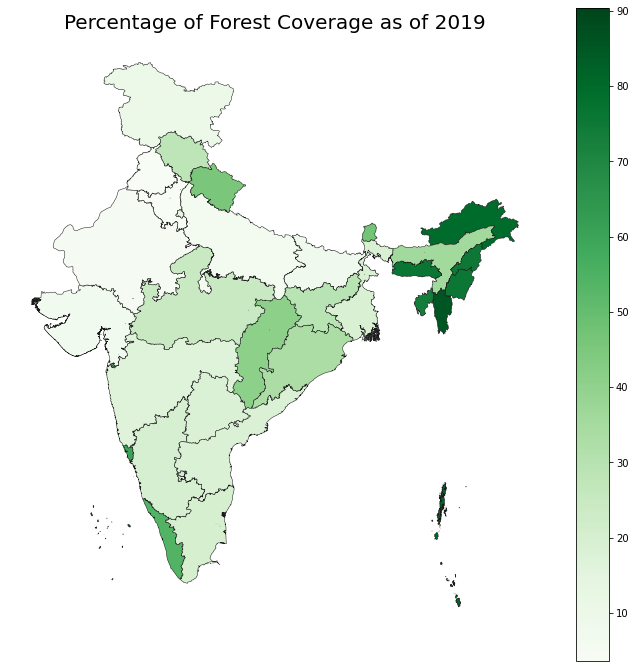

In [6]:
fig, ax = plt.subplots(1, figsize=(12, 12))
ax.axis('off')
ax.set_title('Percentage of Forest Coverage as of 2019',
             fontdict={'fontsize': '20', 'fontweight' : '5'})
fig = merged.plot(column='Percentage of geographical area', cmap='Greens', linewidth=0.5, ax=ax, edgecolor='0.1',legend=True)

<AxesSubplot:xlabel='Percentage of geographical area', ylabel='State/UTs'>

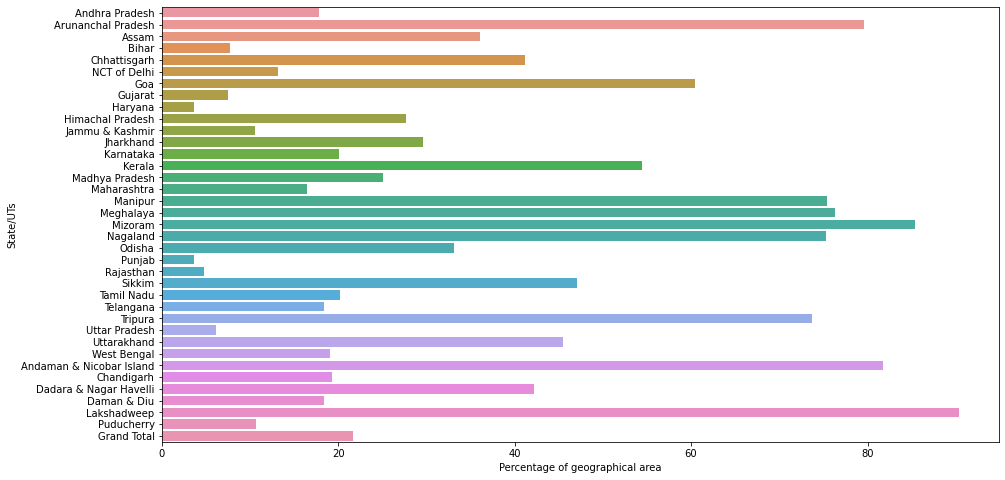

In [7]:
plt.figure(figsize=(15,8))
sns.barplot(x="Percentage of geographical area", y = "State/UTs", data = df1)